# Train yolo11s model training


Ultralytics 8.3.235 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/Smart-city(latest)-4/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.1, dynamic=False, embed=None, epochs=250, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.001, mask_ratio=4, max_det=300, mixup=0.15, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=monitoring-yolo11s-improved, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=Tr

invalid value encountered in less
invalid value encountered in less


                   all        586       1040      0.736      0.706      0.705      0.492
       DefectedManhole        117        138      0.785       0.82       0.84      0.606
               FullBin        101        178      0.706      0.612      0.552      0.339
               Garbage        149        199      0.572      0.457      0.458      0.235
           GoodManhole        117        148      0.723      0.811      0.759       0.56
            ManagedBin        111        155        0.8       0.71      0.756      0.548
               pothole        116        222      0.829      0.824      0.868      0.661
Speed: 0.1ms preprocess, 4.6ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /kaggle/working/runs/detect/monitoring-yolo11s-improved

✅ TRAINING COMPLETE!

⏱️  Total Training Time: 227.66 minutes (13659.84 seconds)
📈 Completed all epochs

📊 Best Validation Metrics:
   • mAP@[.5:.95]: 0.4916
   • mAP@0.5:      0.7053
   • mAP@0.75:     0.5461

💾 Best Mod

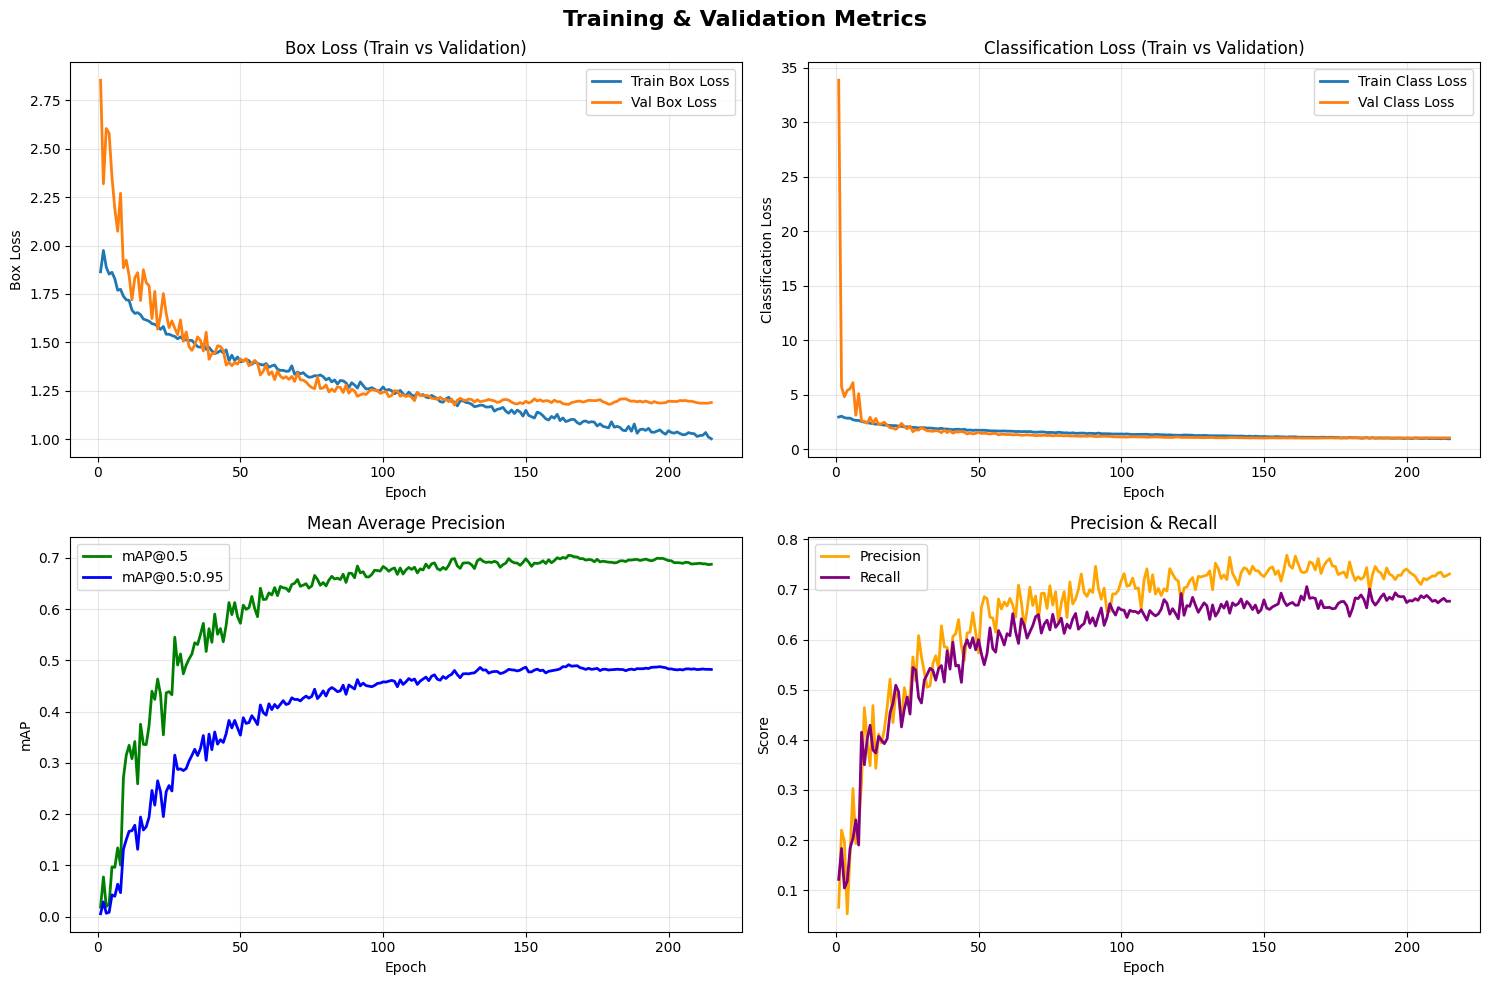


2️⃣ Plotting Precision, Recall, F1-Score Trends...
   ✓ Saved: runs/detect/monitoring-yolo11s-improved/precision_recall_f1_trends.png


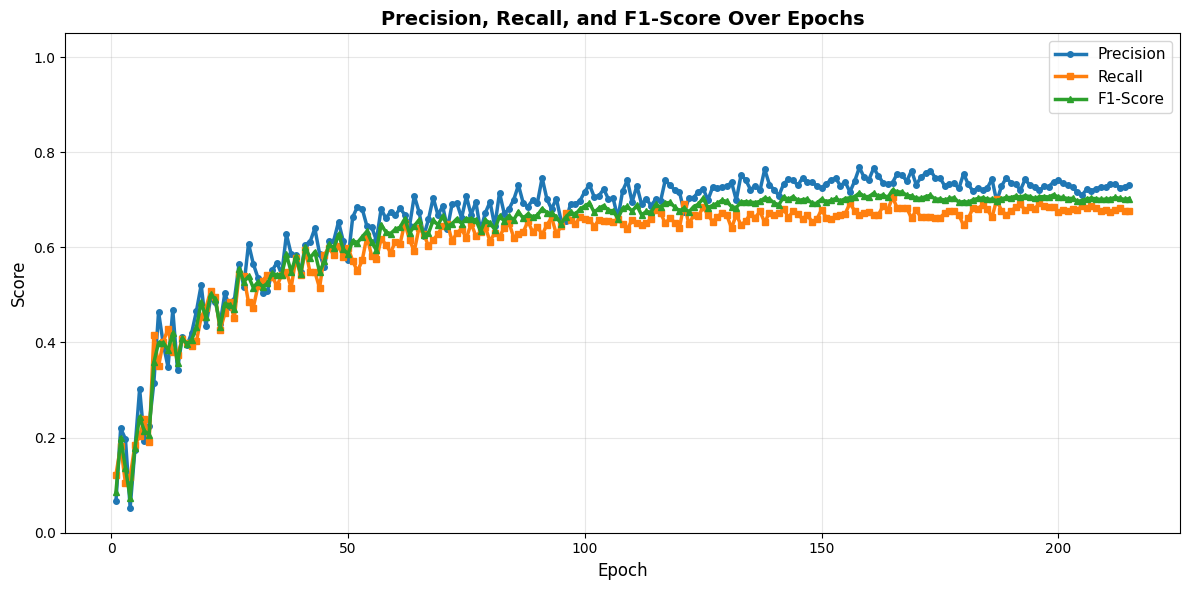


3️⃣ Generating Confusion Matrix...
   ✓ Confusion matrix already generated: runs/detect/monitoring-yolo11s-improved/confusion_matrix.png


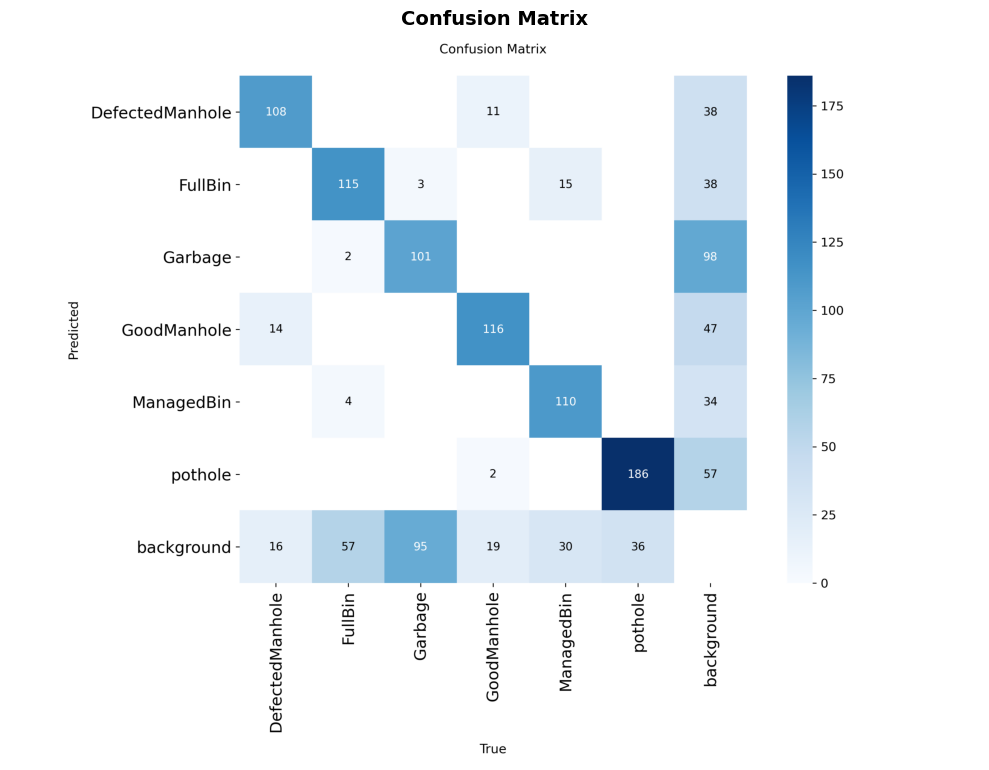


4️⃣ Running Evaluation on Test Set...
Ultralytics 8.3.235 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2223.7±1283.0 MB/s, size: 709.1 KB)
val: Scanning /kaggle/working/Smart-city(latest)-4/test/labels... 578 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 578/578 1.5Kit/s 0.4s
val: /kaggle/working/Smart-city(latest)-4/test/images/dumpsters-being-full-garbage-260nw-272587109_webp.rf.59812b331c4c84025cf221b89a7fff5d.jpg: 1 duplicate labels removed
val: New cache created: /kaggle/working/Smart-city(latest)-4/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 101, len(boxes) = 1001. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     I

invalid value encountered in less
invalid value encountered in less


                   all        578       1001       0.77      0.679      0.746      0.559
       DefectedManhole        114        124      0.882      0.806      0.884      0.692
               FullBin         99        156      0.732      0.551      0.661      0.476
               Garbage        142        211      0.651      0.417       0.51      0.266
           GoodManhole        115        147      0.783      0.789      0.805      0.624
            ManagedBin        108        163      0.746      0.687      0.729       0.56
               pothole        117        200      0.829      0.825      0.888      0.738
Speed: 1.6ms preprocess, 6.2ms inference, 0.0ms loss, 1.4ms postprocess per image
Saving /kaggle/working/runs/detect/val/predictions.json...
Results saved to /kaggle/working/runs/detect/val

5️⃣ Creating Comprehensive Evaluation Metrics Table...

📊 COMPREHENSIVE EVALUATION METRICS (Test Set)
          Class  Precision  Recall  F1-Score  mAP@0.5  mAP@0.5:0.95
DefectedManhole 

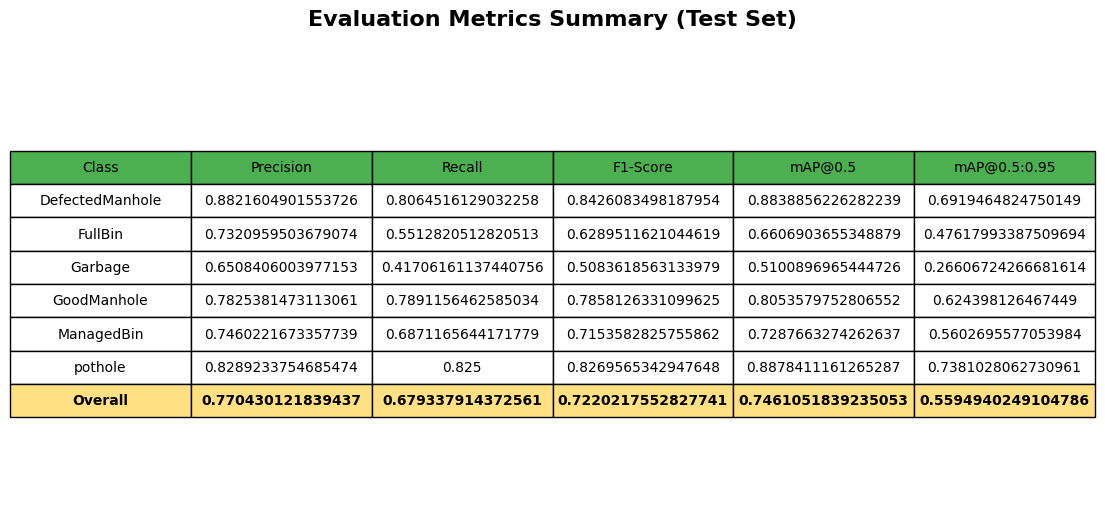


6️⃣ Note: ROC curves are typically used for binary classification.
   For multi-class object detection, we use Precision-Recall curves instead.
   Check the generated PR curves in the results folder.

✅ ALL VISUALIZATIONS COMPLETED!

📁 All results saved in: runs/detect/monitoring-yolo11s-improved/

Generated files:
   • training_validation_curves.png
   • precision_recall_f1_trends.png
   • confusion_matrix.png
   • evaluation_metrics_table.png
   • PR_curve.png (auto-generated)
   • F1_curve.png (auto-generated)


In [7]:
from ultralytics import YOLO
import time

# Load the pre-trained YOLOv11s model
model = YOLO("yolo11s.pt")

# Start timer
start_time = time.time()

# ===================================================================
# 🚀 IMPROVED TRAINING with Strong Augmentation & Early Stopping
# ===================================================================

results = model.train(
    data=f"{dataset.location}/data.yaml",
    
    # ===== Basic Training Parameters =====
    epochs=250,                    # More epochs with early stopping
    imgsz=640,
    batch=16,
    device=0,
    name="monitoring-yolo11s-improved",
    verbose=True,
    
    # ===== Early Stopping (Overfitting Prevention) =====
    patience=50,                   # Stop if no improvement for 30 epochs
    
    # ===== Learning Rate & Optimizer =====
    lr0=0.01,                      # Initial learning rate
    lrf=0.001,                     # Final learning rate (for cosine annealing)
    optimizer='AdamW',             # Better than SGD for small datasets
    cos_lr=True,                   # Enable Cosine Annealing LR schedule
    warmup_epochs=10,              # More warmup (default is 3)
    warmup_momentum=0.5,           # Warmup momentum
    
    # ===== Regularization =====
    weight_decay=0.001,            # L2 regularization (increased from 0.0005)
    dropout=0.1,                   # Dropout for overfitting prevention
    
    # ===== Data Augmentation (STRONG) =====
    hsv_h=0.015,                   # HSV-Hue augmentation
    hsv_s=0.7,                     # HSV-Saturation augmentation
    hsv_v=0.4,                     # HSV-Value augmentation
    degrees=10.0,                  # Rotation augmentation
    translate=0.1,                 # Translation augmentation
    scale=0.5,                     # Scale augmentation (0.5 = ±50%)
    shear=0.0,                     # Shear augmentation
    perspective=0.0001,            # Perspective augmentation
    flipud=0.0,                    # Vertical flip probability
    fliplr=0.5,                    # Horizontal flip probability
    mosaic=1.0,                    # Mosaic augmentation (ENABLED - Very Important!)
    mixup=0.15,                    # MixUp augmentation (15% probability)
    copy_paste=0.1,                # Copy-paste augmentation (10% probability)
    erasing=0.4,                   # Random erasing augmentation
    
    # ===== Loss Function Weights =====
    box=7.5,                       # Box loss gain
    cls=0.5,                       # Class loss gain  
    dfl=1.5,                       # DFL loss gain
    
    # ===== Model Saving =====
    save=True,                     # Save checkpoints
    save_period=10,                # Save every 10 epochs
    
    # ===== Validation =====
    val=True,                      # Enable validation
    plots=True,                    # Save training plots
)

# End timer
end_time = time.time()
training_time = end_time - start_time

# ===================================================================
# 📊 TRAINING SUMMARY
# ===================================================================

print("\n" + "="*70)
print("✅ TRAINING COMPLETE!")
print("="*70)

print(f"\n⏱️  Total Training Time: {training_time/60:.2f} minutes ({training_time:.2f} seconds)")

# Get the best epoch info
if hasattr(results, 'best_epoch'):
    print(f"🏆 Best Epoch: {results.best_epoch}")
    print(f"⚠️  Training stopped at epoch: {results.epochs} (Early stopping activated)")
else:
    print(f"📈 Completed all epochs")

# Metrics
if hasattr(results, "box") and results.box.map is not None:
    print(f"\n📊 Best Validation Metrics:")
    print(f"   • mAP@[.5:.95]: {results.box.map:.4f}")
    print(f"   • mAP@0.5:      {results.box.map50:.4f}")
    print(f"   • mAP@0.75:     {results.box.map75:.4f}")

# Model location
print(f"\n💾 Best Model Saved At:")
print(f"   runs/detect/monitoring-yolo11s-improved/weights/best.pt")

print("\n" + "="*70)
print("🔥 IMPROVEMENTS APPLIED:")
print("="*70)
print("✓ Strong Data Augmentation (Mosaic + MixUp + Erasing)")
print("✓ Cosine Annealing LR Schedule")
print("✓ Extended Warmup (10 epochs)")
print("✓ Increased Weight Decay (0.001)")
print("✓ Early Stopping (patience=30)")
print("✓ AdamW Optimizer")
print("✓ Enhanced Loss Weights (box=7.5, cls=0.5, dfl=1.5)")
print("="*70)

print("\n💡 NOTE: Class weighting handled through loss function weights")
print("   Poor performing classes (Garbage, FullBin) will benefit from:")
print("   • Strong augmentation (especially Mosaic & Erasing)")
print("   • Higher box loss weight (7.5) for better localization")
print("   • More training epochs with early stopping")

# ===================================================================
# 📈 DETAILED VISUALIZATION & EVALUATION
# ===================================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve, auc
import seaborn as sns
import pandas as pd
import glob

print("\n" + "="*70)
print("📊 GENERATING DETAILED VISUALIZATIONS...")
print("="*70)

# Get the results directory
results_dir = "runs/detect/monitoring-yolo11s-improved"

# ===== 1. TRAINING & VALIDATION CURVES =====
print("\n1️⃣ Plotting Training & Validation Curves...")

# Load results.csv
results_csv = f"{results_dir}/results.csv"
if os.path.exists(results_csv):
    df = pd.read_csv(results_csv)
    df.columns = df.columns.str.strip()  # Remove whitespace from column names
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle('Training & Validation Metrics', fontsize=16, fontweight='bold')
    
    # Loss curves
    axes[0, 0].plot(df['epoch'], df['train/box_loss'], label='Train Box Loss', linewidth=2)
    axes[0, 0].plot(df['epoch'], df['val/box_loss'], label='Val Box Loss', linewidth=2)
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Box Loss')
    axes[0, 0].set_title('Box Loss (Train vs Validation)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].plot(df['epoch'], df['train/cls_loss'], label='Train Class Loss', linewidth=2)
    axes[0, 1].plot(df['epoch'], df['val/cls_loss'], label='Val Class Loss', linewidth=2)
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Classification Loss')
    axes[0, 1].set_title('Classification Loss (Train vs Validation)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # mAP curves
    axes[1, 0].plot(df['epoch'], df['metrics/mAP50(B)'], label='mAP@0.5', linewidth=2, color='green')
    axes[1, 0].plot(df['epoch'], df['metrics/mAP50-95(B)'], label='mAP@0.5:0.95', linewidth=2, color='blue')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('mAP')
    axes[1, 0].set_title('Mean Average Precision')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Precision & Recall
    axes[1, 1].plot(df['epoch'], df['metrics/precision(B)'], label='Precision', linewidth=2, color='orange')
    axes[1, 1].plot(df['epoch'], df['metrics/recall(B)'], label='Recall', linewidth=2, color='purple')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Score')
    axes[1, 1].set_title('Precision & Recall')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f"{results_dir}/training_validation_curves.png", dpi=300, bbox_inches='tight')
    print(f"   ✓ Saved: {results_dir}/training_validation_curves.png")
    plt.show()

# ===== 2. PRECISION, RECALL, F1-SCORE LINE GRAPHS =====
print("\n2️⃣ Plotting Precision, Recall, F1-Score Trends...")

if os.path.exists(results_csv):
    fig, ax = plt.subplots(1, 1, figsize=(12, 6))
    
    precision = df['metrics/precision(B)']
    recall = df['metrics/recall(B)']
    f1_score = 2 * (precision * recall) / (precision + recall + 1e-6)
    
    ax.plot(df['epoch'], precision, label='Precision', linewidth=2.5, marker='o', markersize=4)
    ax.plot(df['epoch'], recall, label='Recall', linewidth=2.5, marker='s', markersize=4)
    ax.plot(df['epoch'], f1_score, label='F1-Score', linewidth=2.5, marker='^', markersize=4)
    
    ax.set_xlabel('Epoch', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_title('Precision, Recall, and F1-Score Over Epochs', fontsize=14, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 1.05])
    
    plt.tight_layout()
    plt.savefig(f"{results_dir}/precision_recall_f1_trends.png", dpi=300, bbox_inches='tight')
    print(f"   ✓ Saved: {results_dir}/precision_recall_f1_trends.png")
    plt.show()

# ===== 3. CONFUSION MATRIX =====
print("\n3️⃣ Generating Confusion Matrix...")

# Check if confusion matrix already exists
confusion_matrix_img = glob.glob(f"{results_dir}/confusion_matrix*.png")
if confusion_matrix_img:
    print(f"   ✓ Confusion matrix already generated: {confusion_matrix_img[0]}")
    from PIL import Image
    img = Image.open(confusion_matrix_img[0])
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("   ⚠ Confusion matrix will be generated after validation")

# ===== 4. EVALUATION ON TEST SET =====
print("\n4️⃣ Running Evaluation on Test Set...")

# Load best model
best_model = YOLO(f"{results_dir}/weights/best.pt")

# Evaluate on test set
test_results = best_model.val(
    data=f"{dataset.location}/data.yaml",
    split='test',
    device=0,
    plots=True,
    save_json=True,
    conf=0.25,
    iou=0.6
)

# ===== 5. COMPREHENSIVE EVALUATION METRICS TABLE =====
print("\n5️⃣ Creating Comprehensive Evaluation Metrics Table...")

class_names = ['DefectedManhole', 'FullBin', 'Garbage', 'GoodManhole', 'ManagedBin', 'pothole']

# Create results dataframe
eval_data = {
    'Class': class_names + ['Overall'],
    'Precision': [],
    'Recall': [],
    'F1-Score': [],
    'mAP@0.5': [],
    'mAP@0.5:0.95': []
}

# Get per-class metrics
if hasattr(test_results, 'box'):
    # Per-class metrics
    for i in range(len(class_names)):
        if hasattr(test_results.box, 'p') and len(test_results.box.p) > i:
            precision = test_results.box.p[i]
        else:
            precision = 0
            
        if hasattr(test_results.box, 'r') and len(test_results.box.r) > i:
            recall = test_results.box.r[i]
        else:
            recall = 0
            
        f1 = 2 * (precision * recall) / (precision + recall + 1e-6)
        
        if hasattr(test_results.box, 'ap50') and len(test_results.box.ap50) > i:
            map50 = test_results.box.ap50[i]
        else:
            map50 = 0
            
        if hasattr(test_results.box, 'ap') and len(test_results.box.ap) > i:
            map50_95 = test_results.box.ap[i]
        else:
            map50_95 = 0
        
        eval_data['Precision'].append(precision)
        eval_data['Recall'].append(recall)
        eval_data['F1-Score'].append(f1)
        eval_data['mAP@0.5'].append(map50)
        eval_data['mAP@0.5:0.95'].append(map50_95)
    
    # Overall metrics
    eval_data['Precision'].append(test_results.box.mp if hasattr(test_results.box, 'mp') else 0)
    eval_data['Recall'].append(test_results.box.mr if hasattr(test_results.box, 'mr') else 0)
    eval_data['F1-Score'].append(2 * (eval_data['Precision'][-1] * eval_data['Recall'][-1]) / 
                                  (eval_data['Precision'][-1] + eval_data['Recall'][-1] + 1e-6))
    eval_data['mAP@0.5'].append(test_results.box.map50 if hasattr(test_results.box, 'map50') else 0)
    eval_data['mAP@0.5:0.95'].append(test_results.box.map if hasattr(test_results.box, 'map') else 0)

eval_df = pd.DataFrame(eval_data)

# Display table
print("\n" + "="*90)
print("📊 COMPREHENSIVE EVALUATION METRICS (Test Set)")
print("="*90)
print(eval_df.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print("="*90)

# Save table as image
fig, ax = plt.subplots(figsize=(14, 6))
ax.axis('tight')
ax.axis('off')

table = ax.table(cellText=eval_df.values, colLabels=eval_df.columns,
                cellLoc='center', loc='center',
                colColours=['#4CAF50']*len(eval_df.columns))

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Highlight overall row
for i in range(len(eval_df.columns)):
    table[(len(class_names)+1, i)].set_facecolor('#FFE082')
    table[(len(class_names)+1, i)].set_text_props(weight='bold')

plt.title('Evaluation Metrics Summary (Test Set)', fontsize=16, fontweight='bold', pad=20)
plt.savefig(f"{results_dir}/evaluation_metrics_table.png", dpi=300, bbox_inches='tight')
print(f"\n   ✓ Saved: {results_dir}/evaluation_metrics_table.png")
plt.show()

# ===== 6. ROC CURVES (if available) =====
print("\n6️⃣ Note: ROC curves are typically used for binary classification.")
print("   For multi-class object detection, we use Precision-Recall curves instead.")
print("   Check the generated PR curves in the results folder.")

print("\n" + "="*70)
print("✅ ALL VISUALIZATIONS COMPLETED!")
print("="*70)
print(f"\n📁 All results saved in: {results_dir}/")
print("\nGenerated files:")
print("   • training_validation_curves.png")
print("   • precision_recall_f1_trends.png")
print("   • confusion_matrix.png")
print("   • evaluation_metrics_table.png")
print("   • PR_curve.png (auto-generated)")
print("   • F1_curve.png (auto-generated)")
print("="*70)